In [1]:
!pip install qiskit
!pip install qiskit-aer
!pip uninstall -y qiskit qiskit-machine-learning
!pip install qiskit==0.43.1 qiskit-machine-learning==0.6.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 19.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 29.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 22.8 MB/s  0:00:00
Found existing installation: qiskit 2.6.2
Uninstalling qiskit-2.6.2:
  Successfully uninstalled qiskit-2.6.2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 16.7 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 34.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting re

In [2]:
!pip install qiskit qiskit-ibm-runtime qiskit-machine-learning qiskit_algorithms qiskit-aer

  Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (14 kB)
Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl (9.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 20.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 551.8/551.8 kB 7.7 MB/s  0:00:00
  Attempting uninstall: python-dateutil
    Found existing installation: python-dateutil 2.9.0.post0
    Uninstalling python-dateutil-2.9.0.post0:
      Successfully uninstalled python-dateutil-2.9.0.post0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [qiskit-ibm-runtime]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
holid

In [3]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

In [5]:
df_train= pd.read_csv("train.csv")
df_test= pd.read_csv("test.csv")
df_val= pd.read_csv("validation.csv")

In [6]:
seeds = [0, 1, 2]
pca_components = 8
n_qubits = 4

#### Without Trained Model

In [7]:
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh

# 1. Choose the fake IBM backend
backend = FakeMarrakesh()

print("Fake backend:", backend.name)
print("Backend qubits:", backend.num_qubits)

from sklearn.preprocessing import LabelEncoder

df_train = pd.read_csv("train.csv")

# Define the feature columns present in the dataset (excluding identifier and target)
feature_columns = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']

X_train = df_train[feature_columns].to_numpy(dtype=float)
X_test = df_test[feature_columns].to_numpy(dtype=float)
X_val = df_val[feature_columns].to_numpy(dtype=float)

# Target: Use the categorical crop type column for classification
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train['target'].values)
y_val = label_encoder.transform(df_val['target'].values)
# Removed test set target encoding since df_test doesn't have a 'target' column

# Preprocessing features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=pca_components, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Train features shape (X_train): {X_train_pca.shape}")
print(f"Train targets shape (y_train): {y_train.shape}")


Fake backend: fake_marrakesh
Backend qubits: 156
Train features shape (X_train): (914, 8)
Train targets shape (y_train): (914,)


In [13]:
# ============================================================
# STEP 2: Load saved model and test it on FakeMarrakesh
# ============================================================
import joblib
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from qiskit.circuit.library import ZZFeatureMap, ZFeatureMap, RealAmplitudes, EfficientSU2
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import VQC
from qiskit_algorithms.optimizers import COBYLA, SPSA,ADAM
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import Sampler
from IPython.display import clear_output
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh


# -----------------------------
# 2. Create FakeMarrakesh backend
# -----------------------------
backend = FakeMarrakesh()

print("Using fake backend:", backend.name)


Using fake backend: fake_marrakesh


/tmp/ipykernel_3464/4036480464.py:2: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  best_feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)


Calculating Quantum Kernels...

==================== TRAINING CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.89      0.91      0.90       247
       maize       0.72      0.95      0.82       242
       wheat       0.93      0.74      0.82       425

    accuracy                           0.84       914
   macro avg       0.85      0.87      0.85       914
weighted avg       0.86      0.84      0.84       914


==================== VALIDATION CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.89      0.94      0.91        50
       maize       0.82      0.94      0.88        50
       wheat       0.90      0.72      0.80        50

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.86       150
weighted avg       0.87      0.87      0.86       150



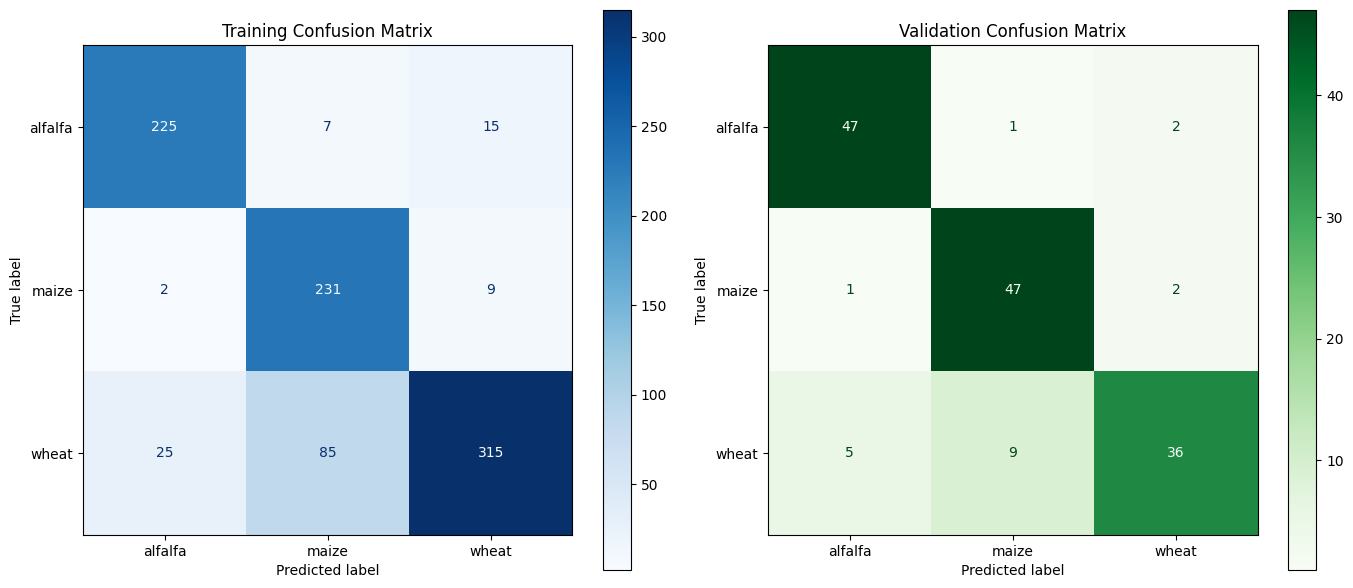


==================== TEST SET PREDICTIONS ====================


,sample_id,predicted_target
0,r2_20ee84e282b608b9,maize
1,r2_3f59edc42ae9243f,maize
2,r2_40d69d894813f204,wheat
3,r2_278ee6f93f7b31ef,maize
4,r2_653d9a22fd070481,maize
5,r2_7fbb4905ffbf8d7e,maize
6,r2_e261f65f34789124,alfalfa
7,r2_53bebc7590cf779d,maize
8,r2_ee7d113fc7f4c99e,maize
9,r2_b01ab6e02585518e,maize


In [14]:
# 1. Initialize ZFeatureMap and Kernel (reps=2)
best_feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)
best_kernel = FidelityStatevectorKernel(feature_map=best_feature_map, auto_clear_cache=False, enforce_psd=True)

# Calculate precomputed kernels using first 4 dimensions of the PCA features
print("Calculating Quantum Kernels...")
K_train_best = best_kernel.evaluate(X_train_pca[:, :4])
K_val_best = best_kernel.evaluate(X_val_pca[:, :4], X_train_pca[:, :4])
K_test_best = best_kernel.evaluate(X_test_pca[:, :4], X_train_pca[:, :4])

# 2. Train the best QSVC model (C=1.0)
best_qsvc = QSVC(
    quantum_kernel="precomputed", C=1.0, class_weight="balanced",
    probability=False, random_state=42,
)
best_qsvc.fit(K_train_best, y_train)

# 3. Generate Predictions
train_pred = best_qsvc.predict(K_train_best)
val_pred = best_qsvc.predict(K_val_best)
test_pred = best_qsvc.predict(K_test_best)

# Retrieve target category names from the LabelEncoder
target_names = list(label_encoder.classes_)

# --- Evaluation Reports ---
print("\n" + "="*20 + " TRAINING CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_train, train_pred, target_names=target_names))

print("\n" + "="*20 + " VALIDATION CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_val, val_pred, target_names=target_names))

# --- Confusion Matrices Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Train Confusion Matrix
cm_train = confusion_matrix(y_train, train_pred)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=target_names)
disp_train.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Training Confusion Matrix")

# Validation Confusion Matrix
cm_val = confusion_matrix(y_val, val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=target_names)
disp_val.plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Validation Confusion Matrix")

plt.tight_layout()
plt.show()

# --- Test Set Predictions ---
print("\n" + "="*20 + " TEST SET PREDICTIONS " + "="*20)
test_pred_labels = label_encoder.inverse_transform(test_pred)
df_test_results = pd.DataFrame({
    'sample_id': df_test['sample_id'],
    'predicted_target': test_pred_labels
})
display(df_test_results.head(10))

### Evaluating the Quantum Kernel on Simulated Hardware (FakeMarrakesh)

In [27]:
from qiskit_aer import AerSimulator
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit.primitives import StatevectorSampler
from qiskit_algorithms.state_fidelities import ComputeUncompute

# 1. Create a simulator modeling the FakeMarrakesh backend
simulator_backend = AerSimulator.from_backend(backend)

# 2. Use a standard StatevectorSampler from qiskit.primitives
sampler = StatevectorSampler()

# Create a State Fidelity object using this sampler
fidelity = ComputeUncompute(sampler=sampler)

# 3. Define the Quantum Kernel using the backend fidelity
best_quantum_kernel_on_backend = FidelityQuantumKernel(
    feature_map=best_feature_map,
    fidelity=fidelity
)

print("Evaluating Quantum Kernels on simulated hardware...")
K_train_sim = best_quantum_kernel_on_backend.evaluate(X_train_pca[:, :4])
K_val_sim = best_quantum_kernel_on_backend.evaluate(X_val_pca[:, :4], X_train_pca[:, :4])
K_test_sim = best_quantum_kernel_on_backend.evaluate(X_test_pca[:, :4], X_train_pca[:, :4])

# 4. Train a new QSVC with the noisy kernel matrix
qsvc_sim = QSVC(quantum_kernel="precomputed", C=1.0, class_weight="balanced", random_state=42)
qsvc_sim.fit(K_train_sim, y_train)

# 5. Predict and Evaluate
val_pred_sim = qsvc_sim.predict(K_val_sim)
print("\n" + "="*20 + " SIMULATED BACKEND VALIDATION REPORT " + "="*20)
print(classification_report(y_val, val_pred_sim, target_names=target_names))

Evaluating Quantum Kernels on simulated hardware...

==================== SIMULATED BACKEND VALIDATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.87      0.94      0.90        50
       maize       0.82      0.92      0.87        50
       wheat       0.88      0.70      0.78        50

    accuracy                           0.85       150
   macro avg       0.86      0.85      0.85       150
weighted avg       0.86      0.85      0.85       150

